# Week 1 — Run it, then discover a real truth yourself

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/nadim7009/flyrank-ml-internship/blob/main/notebooks/01_first_look_and_discovery.ipynb?flush_cache=true)

By the end of this notebook you will have:
1. **Run a real ML pipeline** on real (anonymized) search data and watched a learned model beat a hand-written rule.
2. **Rediscovered a real finding yourself** in ~10 lines of pandas.

No prior ML needed. Everything runs on the small anonymized dataset that ships with this repo — no credentials, no private data.

## 0. Setup (Colab or local)
On Colab this clones the repo and installs requirements. Locally it just moves to the repo root.

In [1]:
import os, sys, subprocess

IN_COLAB = "google.colab" in sys.modules
REPO_URL = "https://github.com/flyrank-bih/flyrank-ml-internship-starter"
REPO_DIR = "flyrank-ml-internship-starter"

if IN_COLAB:
    if not os.path.isdir(REPO_DIR):
        subprocess.run(["git", "clone", "--depth", "1", REPO_URL, REPO_DIR], check=True)
    os.chdir(REPO_DIR)
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", "-r", "requirements.txt"], check=True)
else:
    # find the repo root from wherever this kernel started
    while not os.path.isdir("data/raw") and os.getcwd() != "/":
        os.chdir("..")

print("Working dir:", os.getcwd())
assert os.path.exists("data/raw/content_refresh_anonymized.csv"), "starter CSV not found — are you at the repo root?"
print("Starter data found. You're ready.")

Working dir: (repo root)
Starter data found. You're ready.


## 1. Run the whole pipeline

This runs `scripts/run_all.py`: prepare features → baseline rule → train 3 models → evaluate → PDF.
It takes ~1 minute on the 30,000-row sample.

In [2]:
# Watch it work — each of the 5 steps prints live as it runs (~1 minute total).
!{sys.executable} scripts/run_all.py



▶ Step 1/5 — Prepare features — clean the data, build the feature vector, define the label
Prepared 30,000 rows from 30,000 raw rows
Wrote data/processed/refresh_feature_vector.csv

▶ Step 2/5 — Baseline — a transparent hand-written rule to beat
Wrote baseline queue: data/processed/baseline_refresh_queue.csv
Top-50 declining rate (full data, not the evaluated holdout Precision@50): 0.340

▶ Step 3/5 — Train — logistic regression, decision tree, random forest (client-holdout split)
Trained 3 models on 30,000 rows
Split strategy: client_holdout
Best model: random_forest
Wrote predictions: data/processed/model_predictions.csv
Wrote model results: outputs/model_results.json

▶ Step 4/5 — Evaluate — ranked refresh queue, charts, and the Markdown report
Wrote final refresh queue: outputs/refresh_queue.csv
Wrote model report: outputs/model_report.md
Wrote charts in: outputs/charts

▶ Step 5/5 — Report — a shareable PDF summary
Wrote PDF report: outputs/flyrank_refresh_model_results.pdf

Pipe

### What just happened?
The pipeline ranked every page for "refresh review" two ways: a **hand-written rule baseline** and a **learned model**. Let's compare them on **Precision@50** — of the top 50 pages each says to fix first, how many are actually declining?

In [3]:
import json
res = json.load(open("outputs/model_results.json"))

base = res["baseline"]["baseline_precision_at_50"]
rf   = res["models"]["random_forest"]["precision_at_50"]

print(f"Hand-written rule  Precision@50: {base:.3f}   (~{round(base*50)} of the top 50 right)")
print(f"Random forest      Precision@50: {rf:.3f}   (~{round(rf*50)} of the top 50 right)")
print(f"\nThe learned model roughly {rf/base:.1f}x the rule on this metric.")
print("Validation split used:", res["split_strategy"], "(pages from a client are never in both train and test)")

Hand-written rule  Precision@50: 0.240   (~12 of the top 50 right)
Random forest      Precision@50: 0.680   (~34 of the top 50 right)

The learned model roughly 2.8x the rule on this metric.
Validation split used: client_holdout (pages from a client are never in both train and test)


You just ran a real ML system on real search data and saw a learned ranking beat a fixed rule. Now open `outputs/model_report.md` and skim it — that Markdown report is the *shape* of what your own capstone should produce.

## 2. Discover a real truth yourself

The safest, most satisfying early wins are **things you find in the data** — un-leakable, and they *are* the core lesson. Run the three cells below. Each is ~10 lines of pandas and each overturns a common SEO belief.

Every number is **computed live from the shipped CSV** — nothing is hardcoded.

In [4]:
import pandas as pd, numpy as np
df = pd.read_csv("data/raw/content_refresh_anonymized.csv")
print(df.shape[0], "rows,", df.shape[1], "columns")
df.head(3)

30000 rows, 44 columns


             content_id          client_id  ...  trend_direction  trend_pct
0  content_304f48230142  client_f369cb89fc  ...             down      -41.4
1  content_a1fb4e703a9e  client_4e07408562  ...             down      -57.7
2  content_9aa793d4d895  client_7f2253d7e2  ...             down      -60.9

[3 rows x 44 columns]

### Discovery A — "High search volume means more traffic." Does it?

In [5]:
corr = df["search_volume"].corr(df["impressions_90d"])
print(f"Correlation between search_volume and impressions_90d: {corr:.3f}")
print("Near zero -> keyword search volume barely predicts the traffic a page actually gets.")

Correlation between search_volume and impressions_90d: 0.001
Near zero -> keyword search volume barely predicts the traffic a page actually gets.


### Discovery B — the CTR cliff by position
Click-through rate is not flat: it collapses as you move down the results.

position_tier
page_1      0.3548
top_3       0.3341
striking    0.2558
page_3_5    0.1424
deep        0.0554


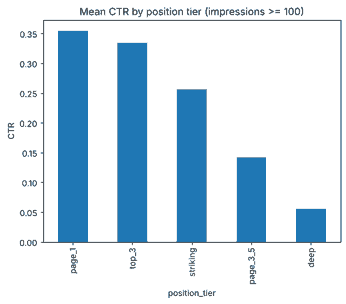

In [6]:
visible = df[df["impressions_90d"] >= 100]
ctr_by_pos = visible.groupby("position_tier")["ctr"].mean().sort_values(ascending=False)
print(ctr_by_pos.round(4).to_string())
ctr_by_pos.plot(kind="bar", title="Mean CTR by position tier (impressions >= 100)", ylabel="CTR");

### Discovery C — is longer content the lever?
Compare word count for **declining** vs **growing** pages.

In [7]:
wc = df.groupby("trend_direction")["word_count"].median()
print(wc.round(0).to_string())
print("\n'down' vs 'up' pages have almost the same median word count -> length is not the lever.")

trend_direction
down      2909.0
flat      2698.0
new       2239.0
stable    2912.0
up        2848.0

'down' vs 'up' pages have almost the same median word count -> length is not the lever.


## 3. 🔧 Your turn

Pick **one** of these and write a few lines below. This is your Week-1 discovery — you'll reference it in your Week-1 research-question write-up (on the InternHQ board).

- Redo Discovery A but only for pages with `impressions_90d > 0` — does the correlation change?
- In Discovery B, which `content_type` has the worst CTR *at the same position tier*?
- Find another belief to test: does `content_age_days` relate to `trend_direction`? Does `avg_position` relate to `ctr`?

**Rules:** describe what you observe as *observed / directional* — never "I proved Google's algorithm." Keep client data out of anything you publish.

In [8]:
# Your discovery here
# Quick check on the first idea: Discovery A with impressions_90d > 0
pos = df[df["impressions_90d"] > 0]
print(f"Rows with impressions_90d > 0: {len(pos)} of {len(df)}")
print(f"Pearson:  {pos['search_volume'].corr(pos['impressions_90d']):.3f}")
print(f"Spearman: {pos['search_volume'].corr(pos['impressions_90d'], method='spearman'):.3f}")

# My discovery: does content age relate to trend_direction?
df["is_down"] = df["trend_direction"].eq("down")
by_age = (df.groupby(["age_tier_order", "age_tier"])["is_down"]
            .agg(pages="size", share_down="mean")
            .droplevel(0))
print("\nShare of pages trending down, by age tier:")
print(by_age.round(3).to_string())

# Could this just be client mix? Repeat the comparison inside each client.
df["younger"] = df["content_age_days"] <= 180
g = df.groupby(["client_id", "younger"])["is_down"].agg(["mean", "size"]).unstack()
g = g[(g["size"] >= 30).all(axis=1)]          # both groups need at least 30 pages
gap = g[("mean", True)] - g[("mean", False)]   # younger minus older
print(f"\nClients with >=30 pages in both age groups: {len(g)}")
print(f"Younger pages decline more often in {(gap > 0).sum()} of them; median gap {gap.median():+.3f}")


Rows with impressions_90d > 0: 30000 of 30000
Pearson:  0.001
Spearman: -0.029

Share of pages trending down, by age tier:
          pages  share_down
age_tier                   
31-90       492       0.669
91-180    11780       0.626
181-365   11368       0.515
365+       6360       0.426

Clients with >=30 pages in both age groups: 12
Younger pages decline more often in 7 of them; median gap +0.020


### What I found

Pages trending down tend to be younger. In the pooled data, 67% of pages aged 31-90 days are trending down, against 43% of pages older than a year, and the share drops at every age tier.

Before trusting that, I checked it inside each client. Only 12 clients have at least 30 pages on both sides of a 180-day cut. Younger pages decline more often in 7 of those 12, and the median gap is about 2 percentage points. So most of the pooled pattern looks like client mix (clients with a lot of new content also have more declining pages) rather than age on its own. My reading: the age pattern is observed in the pooled data, but weak and unclear once you compare pages within the same client.

Side note on the first idea: every row already has `impressions_90d > 0`, so that filter changes nothing. The correlation stays near zero (Pearson 0.001, Spearman -0.03).

The random forest in my run scored Precision@50 = 0.680 against the rule's 0.240, about 2.8x. That sits inside the 0.68-0.74 range GUIDE.md gives for different library versions.


### Save your work
**Colab:** *File → Save a copy in GitHub* (writes to your own repo — that's your submission) and *File → Save a copy in Drive* (so the session doesn't evaporate).

Next: `02_your_first_readable_model.ipynb` — where the model becomes a rule you can read.